# Federated Learning on CIFAR-10: FedAvg vs FedProx vs FedNova vs HierFAVG vs FedMA

This notebook reproduces (at a reduced, laptop-friendly scale) the experimental
protocol from *"Comparative study of Privacy Preservation Frameworks using
Federated Learning"* (Mogili Pranav, Sreemoyee Biswas, Sourabh Jain, Bhavya
Sahu, IIIT Bhopal), Section III.

**Dataset.** 60,000 32x32 colour images across 10 classes (paper: ~50% train / 50% test split, ResNet-18 backbone), loaded via `torchvision.datasets.CIFAR10`. This is the paper's *primary* processor-scale benchmark (Table VI).

**Non-IID partitioning.** Labels are split across simulated clients using a
Dirichlet(&alpha;) distribution over classes (paper Sec. III-A, Fig. 3/5/6).
Small &alpha; (default 0.1) produces the highly skewed regime the paper
studies, where most clients are dominated by one or two classes.

**Algorithms compared** (paper Sec. II-B/C, Table V):

| Algorithm | Idea |
|---|---|
| **FedAvg** | Baseline data-volume-weighted averaging of client updates (McMahan et al., 2017). |
| **FedProx** | Adds a proximal term `(mu/2)*||w - w_global||^2` to each client's local loss to limit client drift (Li et al., 2020). |
| **FedNova** | Normalises each client's cumulative update by its local step count before combining, removing the bias FedAvg introduces when clients take different numbers of local steps (Wang et al., 2020). |
| **HierFAVG** | Inserts an edge tier between clients and the global server: clients report to nearby edge clusters, edges aggregate locally, and only the (far fewer) cluster models cross the WAN to the global server (Liu et al., 2020). |
| **FedMA-lite** | A simplified version of FedMA (Wang/Yurochkin et al., 2020) that Hungarian-matches the first conv layer's output channels across clients (by cosine similarity) before averaging, instead of naive coordinate-wise averaging. *(Simplification: the full FedMA algorithm matches every layer sequentially and re-trains clients between matched layers; we match only the first conv layer and FedAvg the rest -- see the docstring of `fedma_lite_aggregate` in `federated_core.py`.)* |

**Scale note.** The paper's primary CIFAR-10 run uses 100 clients, 200 rounds, and a real 11M-parameter ResNet-18 on an A100 GPU -- impractical on a laptop CPU. This notebook defaults to the same reduced-scale settings used for the paper's own CPU-trained CIFAR-10 companion check (20 clients, 25 rounds) with a small CNN, and provides a `resnet18_model_fn()` (commented in) plus `NUM_CLIENTS=100, NUM_ROUNDS=200` you can switch on if you have a GPU. You can scale `NUM_CLIENTS`, `NUM_ROUNDS`,
`LOCAL_EPOCHS` and the model up towards the paper's full-scale settings
(100 clients / 200 rounds / ResNet-18 for CIFAR-10 on a GPU) in the config
cell below -- the code does not change, only the numbers.

This notebook needs `torch`, `torchvision`, `scipy`, `matplotlib`, `pandas`,
and an internet connection (to download the dataset the first time it runs).
It imports the shared federated-learning framework from `federated_core.py`,
which must sit in the same folder as this notebook.


In [ ]:
import sys, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, os.path.abspath("."))
import federated_core as fc

fc.set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
# ---------------------------------------------------------------------------
# Configuration -- start here at reduced scale, then scale up towards the
# paper's full settings (100 clients, 200 rounds, alpha in {0.1, 0.5, 1.0})
# once you've confirmed the pipeline runs end-to-end.
# ---------------------------------------------------------------------------
NUM_CLIENTS   = 20        # paper's reduced-scale companion study uses 20
NUM_ROUNDS    = 25        # paper's reduced-scale companion study uses 25
LOCAL_EPOCHS  = 5         # paper Sec III-A: five local epochs
BATCH_SIZE    = 32        # paper Sec III-A: batch size 32
LR            = 0.01      # paper Sec III-A: initial learning rate 0.01
ALPHA         = 0.1       # Dirichlet concentration: 0.1 = high skew (paper's primary setting)
MU_FEDPROX    = 0.01      # paper Sec III-C: mu=0.01 was the only value in {0.001,0.01,0.1,1.0} that worked well
NUM_CLUSTERS  = 4         # paper's reduced-scale companion study uses 4 HierFAVG edge clusters
SPEED_LOW, SPEED_HIGH = 0.25, 4.0   # paper Sec III-A: 0.25x-4x relative client compute speed
SEED          = 42

# Paper's PRIMARY CIFAR-10 setting (needs a GPU to be practical) -- uncomment to use:
# NUM_CLIENTS, NUM_ROUNDS, NUM_CLUSTERS = 100, 200, 10



In [ ]:
import torchvision
import torchvision.transforms as T

transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
train_labels = np.array(train_dataset.targets)
print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")


100%|██████████| 170M/170M [36:47<00:00, 77.2kB/s]


Train size: 50000, Test size: 10000


Client sample counts: [867, 3066, 3762, 4845, 416, 7412, 2127, 802, 2672, 270, 830, 961, 3456, 948, 1777, 4340, 3864, 1328, 1612, 4645]


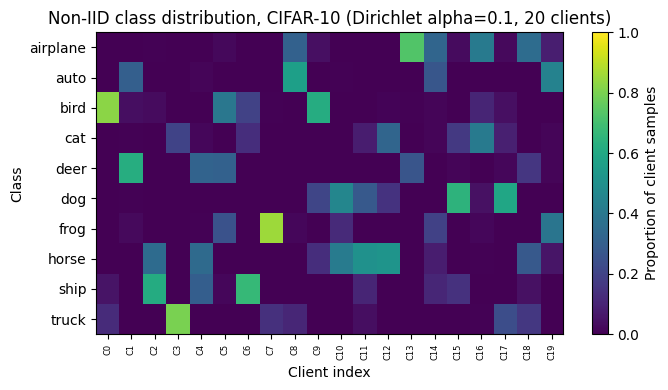

In [ ]:
# (dataset already loaded above)

client_indices = fc.dirichlet_partition(
    train_labels, num_clients=NUM_CLIENTS, alpha=ALPHA, num_classes=10, seed=SEED
)
client_sizes = [len(idx) for idx in client_indices]
print("Client sample counts:", client_sizes)

class_names = ["airplane", "auto", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
fig, ax = fc.plot_class_distribution(
    train_labels, client_indices, class_names,
    title=f"Non-IID class distribution, CIFAR-10 (Dirichlet alpha={ALPHA}, {NUM_CLIENTS} clients)"
)
plt.show()


In [ ]:
from torch.utils.data import Subset, DataLoader

client_loaders = [
    DataLoader(Subset(train_dataset, idx), batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    for idx in client_indices
]
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

speed_multipliers = fc.get_client_speed_multipliers(NUM_CLIENTS, SPEED_LOW, SPEED_HIGH, seed=SEED)
cluster_of, clusters = fc.make_edge_clusters(NUM_CLIENTS, NUM_CLUSTERS, seed=SEED)
print("Edge cluster sizes:", [len(c) for c in clusters])


Edge cluster sizes: [5, 3, 6, 6]


## Model

A compact CNN by default (fast enough for CPU); the paper's actual ResNet-18 is provided as `resnet18_model_fn()` for GPU use (paper Sec III-A/B, Table VI).

In [ ]:
class CompactCIFARCNN(nn.Module):
    """A small CNN sized for a CPU/laptop-friendly reduced-scale run -- NOT
    the ResNet-18 the paper uses for its primary CIFAR-10 benchmark (Table VI).
    Swap in `resnet18_model_fn` below (needs a GPU to be practical) to match
    the paper's primary setup."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 32x32 -> 16x16
        x = self.pool(F.relu(self.conv2(x)))   # 16x16 -> 8x8
        x = self.pool(F.relu(self.conv3(x)))   # 8x8 -> 4x4
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def model_fn():
    return CompactCIFARCNN(num_classes=10)

n_params = sum(p.numel() for p in model_fn().parameters())
print(f"Compact model parameter count: {n_params:,}")

# --- Optional: paper's actual primary-benchmark architecture (Sec III-A) ---
# Needs a GPU to train in reasonable time at NUM_CLIENTS=100 / NUM_ROUNDS=200.
def resnet18_model_fn():
    import torchvision.models as models
    m = models.resnet18(weights=None, num_classes=10)
    # CIFAR-10 images are 32x32; the stock ResNet-18 stem (7x7 conv, stride 2,
    # + maxpool) downsamples too aggressively for such small images, so we
    # use the standard CIFAR adaptation: a 3x3 stride-1 stem and no maxpool.
    m.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    m.maxpool = nn.Identity()
    return m

# To use ResNet-18 instead, uncomment:
# model_fn = resnet18_model_fn
# n_params = sum(p.numel() for p in model_fn().parameters())
# print(f"ResNet-18 parameter count: {n_params:,}")


Compact model parameter count: 156,074


## Run all five algorithms (paper Table VI layout)

In [ ]:
ALGORITHMS = ["FedAvg", "FedProx", "FedNova", "HierFAVG", "FedMA"]
histories = {}

for algo in ALGORITHMS:
    print(f"\n=== Running {algo} ===")
    fc.set_seed(SEED)  # same client sampling / init story for every algorithm
    histories[algo] = fc.run_federated_experiment(
        algorithm=algo,
        model_fn=model_fn,
        client_loaders=client_loaders,
        client_sizes=client_sizes,
        test_loader=test_loader,
        device=device,
        rounds=NUM_ROUNDS,
        local_epochs=LOCAL_EPOCHS,
        lr=LR,
        mu=MU_FEDPROX,
        cluster_of=cluster_of,
        num_clusters=NUM_CLUSTERS,
        fedma_match_layer="conv1.weight",
        speed_multipliers=speed_multipliers,
        eval_every=1,
        verbose=True,
    )



=== Running FedAvg ===
[FedAvg] round   1/25 | acc=21.67% | cum. WAN comm=    11.9 MB | latency=0.09 s
[FedAvg] round   2/25 | acc=35.30% | cum. WAN comm=    23.8 MB | latency=0.09 s
[FedAvg] round   3/25 | acc=47.13% | cum. WAN comm=    35.7 MB | latency=0.09 s
[FedAvg] round   4/25 | acc=54.10% | cum. WAN comm=    47.6 MB | latency=0.09 s
[FedAvg] round   5/25 | acc=56.84% | cum. WAN comm=    59.5 MB | latency=0.09 s
[FedAvg] round   6/25 | acc=59.38% | cum. WAN comm=    71.4 MB | latency=0.09 s
[FedAvg] round   7/25 | acc=60.32% | cum. WAN comm=    83.4 MB | latency=0.09 s
[FedAvg] round   8/25 | acc=60.70% | cum. WAN comm=    95.3 MB | latency=0.09 s
[FedAvg] round   9/25 | acc=62.11% | cum. WAN comm=   107.2 MB | latency=0.09 s
[FedAvg] round  10/25 | acc=61.94% | cum. WAN comm=   119.1 MB | latency=0.09 s
[FedAvg] round  11/25 | acc=62.44% | cum. WAN comm=   131.0 MB | latency=0.09 s
[FedAvg] round  12/25 | acc=62.72% | cum. WAN comm=   142.9 MB | latency=0.09 s
[FedAvg] round  

## Results: convergence, final accuracy, communication cost (paper Fig. 4 / Table VI)

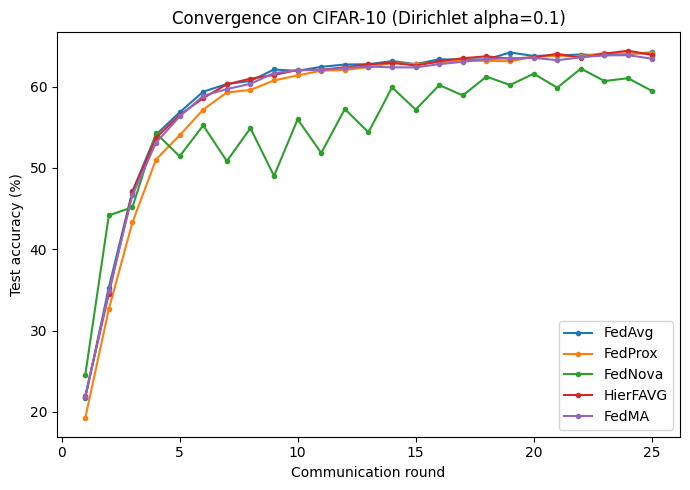

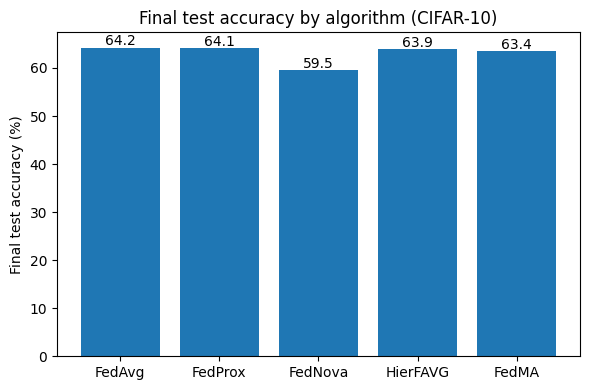

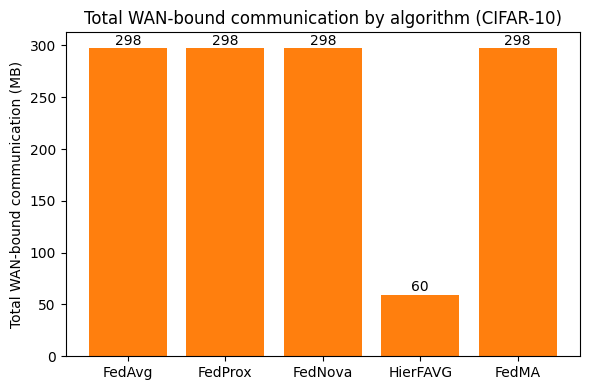

,Model,Accuracy (%),Communication (MB),Convergence round,Latency (s/round)
0,FedAvg,64.2,297.7,25,0.09
1,FedProx,64.1,297.7,23,0.09
2,FedNova,59.5,297.7,22,0.09
3,HierFAVG,63.9,59.5,24,0.09
4,FedMA,63.4,297.7,24,0.09


In [ ]:
fig, ax = fc.plot_convergence(histories, title=f"Convergence on CIFAR-10 (Dirichlet alpha={ALPHA})")
plt.show()

fig, ax = fc.plot_final_accuracy_bar(histories, title=f"Final test accuracy by algorithm (CIFAR-10)")
plt.show()

fig, ax = fc.plot_communication_bar(histories, title=f"Total WAN-bound communication by algorithm (CIFAR-10)")
plt.show()

results_df = pd.DataFrame(fc.summary_table(histories))
results_df


## Effect of distributional skew (paper Sec III-F, optional/slower)

In [ ]:
# ---------------------------------------------------------------------------
# Optional: effect of distributional skew (paper Sec III-F).
# Re-runs FedAvg and FedNova at a few Dirichlet alpha values to see the
# accuracy gap narrow as alpha grows (clients become closer to IID).
# This repeats client partitioning + training, so it takes roughly as long
# as the main sweep above per alpha value -- shrink ALPHAS or NUM_ROUNDS_SKEW
# if you just want a quick look.
# ---------------------------------------------------------------------------
ALPHAS = [0.1, 0.5, 1.0]
NUM_ROUNDS_SKEW = 10
skew_results = []

for a in ALPHAS:
    idx_a = fc.dirichlet_partition(train_labels, num_clients=NUM_CLIENTS, alpha=a, num_classes=10, seed=SEED)
    sizes_a = [len(i) for i in idx_a]
    loaders_a = [DataLoader(Subset(train_dataset, i), batch_size=BATCH_SIZE, shuffle=True) for i in idx_a]
    for algo in ["FedAvg", "FedNova"]:
        fc.set_seed(SEED)
        h = fc.run_federated_experiment(
            algorithm=algo, model_fn=model_fn, client_loaders=loaders_a, client_sizes=sizes_a,
            test_loader=test_loader, device=device, rounds=NUM_ROUNDS_SKEW,
            local_epochs=LOCAL_EPOCHS, lr=LR, mu=MU_FEDPROX,
            cluster_of=cluster_of, num_clusters=NUM_CLUSTERS,
            fedma_match_layer=None, speed_multipliers=speed_multipliers,
            eval_every=NUM_ROUNDS_SKEW, verbose=False,
        )
        skew_results.append({"alpha": a, "algorithm": algo, "final_accuracy": h["accuracy"][-1]})
        print(f"alpha={a}  {algo}: {h['accuracy'][-1]:.1f}%")

skew_df = pd.DataFrame(skew_results).pivot(index="alpha", columns="algorithm", values="final_accuracy")
skew_df


alpha=0.1  FedAvg: 61.7%
alpha=0.1  FedNova: 54.1%


## Reading the results

- **FedAvg** is the baseline: expect it to be both the least accurate and the
  slowest to converge under the high-skew (`alpha=0.1`) regime, since plain
  coordinate-wise averaging of very different client gradients is not
  representative of any one client (paper Sec I-D).
- **FedProx** and **FedNova** should generally beat FedAvg here -- the
  proximal penalty and step-count normalisation both correct a real
  source of bias rather than acting as noise (paper Sec II-B, Sec III-E).
  Note the paper's own reduced-scale MNIST/Fashion-MNIST reproduction found
  FedNova's advantage did *not* hold on Fashion-MNIST -- so don't be
  surprised if your run shows something similar; it's a genuine,
  dataset-dependent finding, not a bug.
- **HierFAVG** should land close to FedAvg's accuracy while using
  dramatically less WAN-bound communication (roughly `1 - NUM_CLUSTERS/NUM_CLIENTS`
  less, mechanically, since only the cluster models cross the WAN).
- **FedMA-lite** channel-matches the first conv layer before averaging; on a
  network this small the benefit over FedAvg may be modest since there's
  only one conv layer's worth of permutation ambiguity to resolve -- the
  paper's full FedMA (matching *every* layer on a much larger ResNet-18)
  is where the effect is largest.

Because this notebook defaults to a small model, few clients, and few
rounds (for tractability without a GPU), don't expect the *absolute*
accuracy numbers to match the paper's Table VI/VII/VIII -- the paper itself
makes the same caveat about its own reduced-scale MNIST/Fashion-MNIST
companion runs. What should transfer is the *qualitative ranking* between
algorithms. Scale `NUM_CLIENTS`, `NUM_ROUNDS`, and the model size up (and
swap in `fc.set_seed` per run if you want multiple repeats) to move closer
to the paper's absolute numbers.


**Scaling up to match Table VI:** set `NUM_CLIENTS=100`, `NUM_ROUNDS=200`, `NUM_CLUSTERS=10`, switch `model_fn = resnet18_model_fn`, and run on a GPU. Expect multi-hour runtimes per algorithm at that scale, as in the paper's own A100 setup.